# LightGBM 최종 테스트

거시 포함 · L1=0 · L2=1.0. 학습 정답은 2025Q4까지, 테스트는 2026Q1~Q3(h=1~3)입니다. 설정은 테스트 전에 고정했으며 이후 재튜닝하지 않았습니다. 현재 수정치 기반 평가로, 2027년 예측·과거 공개시점 재현 검증은 아닙니다.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display

RUN_ID="lightgbm_v002_final_test_l2_20261104_01"
ROOT=next((p for p in [Path.cwd(),*Path.cwd().parents] if (p/"artifacts"/RUN_ID).is_dir()),None)
if ROOT is None:raise FileNotFoundError("프로젝트 루트 또는 notebooks에서 실행하세요.")
RUN=ROOT/"artifacts"/RUN_ID
FIGURES=RUN/"figures"
FIGURES.mkdir(exist_ok=True)
meta=json.loads((RUN/"run_metadata.json").read_text(encoding="utf-8"))
rows=pd.read_parquet(RUN/"final_test_predictions.parquet")
metrics=pd.read_csv(RUN/"metrics.csv",dtype={"group_value":"string"})
common=pd.read_csv(RUN/"metrics_baseline_common_rows.csv",dtype={"group_value":"string"})
scored=rows[rows.evaluation_status.eq("scored")]
font_manager.fontManager.addfont("C:/Windows/Fonts/malgun.ttf")
plt.rcParams.update({"font.family":"Malgun Gothic","axes.unicode_minus":False,"axes.spines.top":False,"axes.spines.right":False})
ACTUAL,PRED="target_export_value_usd","predicted_export_value_usd"
def display_metrics(df):
    columns=[c for c in ["model_id","scope","group_value","n","wape","mae","rmse","smape"] if c in df]
    display(df[columns].rename(columns={"model_id":"모델","scope":"거리 범위","group_value":"구분","n":"평가 행","wape":"WAPE (%)","mae":"MAE (USD)","rmse":"RMSE (USD)","smape":"sMAPE (%)"}))
display(pd.DataFrame({"항목":["학습 유효 행","테스트 전체","평가 가능","정답 결측"],"행 수":[meta["fit_rows"],meta["test_rows"],meta["scored_rows"],meta["missing_actual_rows"]]}))


,항목,행 수
0,학습 유효 행,34745
1,테스트 전체,480
2,평가 가능,447
3,정답 결측,33


## 1. 테스트 성능

h1~3 전체와 운영 거리의 교집합 h2~3을 구분합니다. 3분기 테스트로 h4~5·연간 성능을 확인할 수는 없습니다. 지표는 낮을수록 좋습니다.

In [2]:
display_metrics(metrics[metrics.group_by.eq("overall")])
display_metrics(metrics[metrics.group_by.eq("horizon_quarters") & metrics.scope.eq("h1_3")])


,모델,거리 범위,구분,평가 행,WAPE (%),MAE (USD),RMSE (USD),sMAPE (%)
0,lightgbm,h1_3,all,447,26.658754,3.816940e+06,1.863150e+07,56.729466
32,lightgbm,h2_3,all,300,29.519846,4.512394e+06,2.147374e+07,59.284191


,모델,거리 범위,구분,평가 행,WAPE (%),MAE (USD),RMSE (USD),sMAPE (%)
29,lightgbm,h1_3,1,147,19.426932,2.397646e+06,1.070063e+07,51.515742
30,lightgbm,h1_3,2,151,24.417310,3.455653e+06,1.713113e+07,57.661388
31,lightgbm,h1_3,3,149,33.972795,5.583320e+06,2.512006e+07,60.928776


## 2. 기준선과 공통 행 비교

둘 다 예측 가능한 동일 행만 비교합니다. 이번 테스트에서는 Seasonal Naive의 WAPE가 더 낮았습니다. 테스트 결과를 보고 모델을 다시 선택·튜닝하지 않았습니다.

In [3]:
display_metrics(common[common.group_by.eq("overall")])


,모델,거리 범위,구분,평가 행,WAPE (%),MAE (USD),RMSE (USD),sMAPE (%)
0,lightgbm,h1_3,all,440,26.641151,3.875088e+06,1.877911e+07,54.577686
32,lightgbm,h2_3,all,297,29.508771,4.556249e+06,2.158191e+07,57.961101
63,seasonal_naive,h1_3,all,440,25.752000,3.745757e+06,1.700842e+07,52.092329
95,seasonal_naive,h2_3,all,297,26.245991,4.052465e+06,1.830000e+07,52.555621


## 3. 실측값·예측값 산점도

대각선에 가까울수록 일치합니다. 정답이 있는 447개 예측, 단위는 백만 USD입니다.

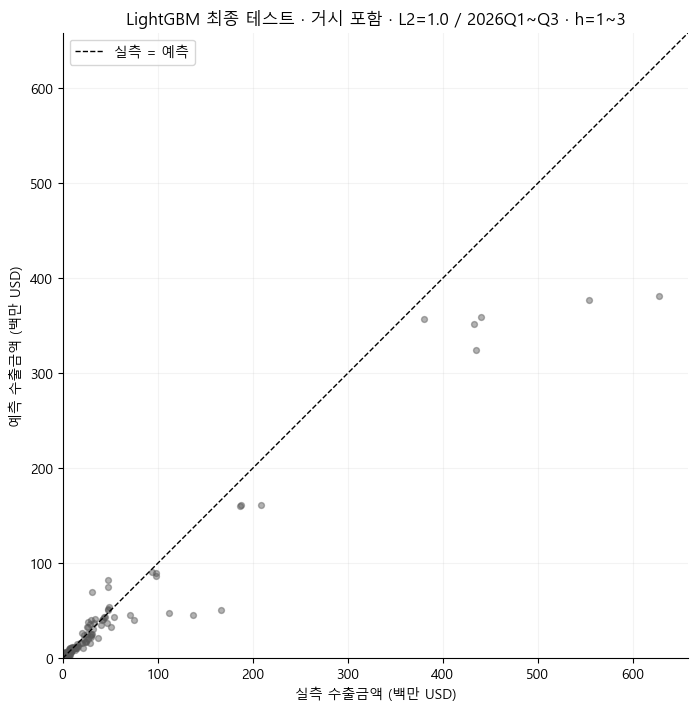

In [4]:
fig,ax=plt.subplots(figsize=(8,7),layout="constrained")
limit=float(scored[[ACTUAL,PRED]].max().max())/1e6*1.05
ax.scatter(scored[ACTUAL].to_numpy(dtype=float)/1e6,scored[PRED].to_numpy(dtype=float)/1e6,s=18,alpha=.45,color="#555555")
ax.plot([0,limit],[0,limit],"k--",linewidth=1,label="실측 = 예측")
ax.set(xlim=(0,limit),ylim=(0,limit),xlabel="실측 수출금액 (백만 USD)",ylabel="예측 수출금액 (백만 USD)",title="LightGBM 최종 테스트 · 거시 포함 · L2=1.0 / 2026Q1~Q3 · h=1~3")
ax.set_aspect("equal",adjustable="box");ax.grid(alpha=.15);ax.legend()
fig.savefig(FIGURES/"final_test_actual_vs_predicted.png",dpi=160)
plt.show()


## 4. 국가·제품별 실측·예측 예시

2025Q4에 고정한 하나의 모델로 2026Q1~Q3를 예측했습니다. 중국 립·베트남 스킨케어를 표시하며 아래 선택값을 바꿀 수 있습니다. 국가·제품별 세로축 범위는 다릅니다.

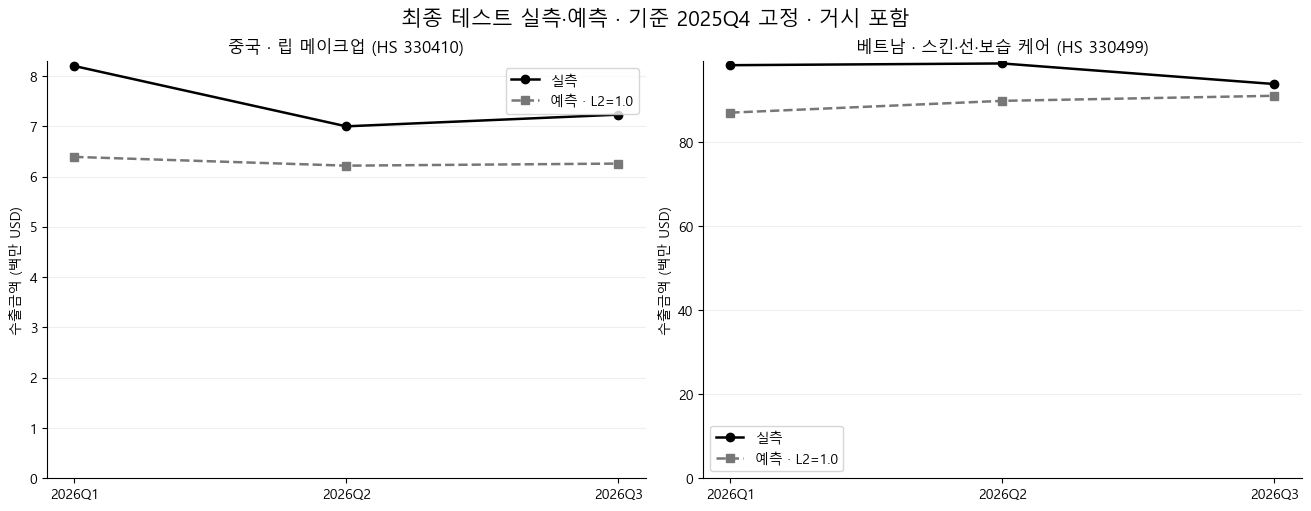

In [5]:
examples=[("CHN","330410","중국 · 립 메이크업"),("VNM","330499","베트남 · 스킨·선·보습 케어")]
targets=["2026Q1","2026Q2","2026Q3"]
fig,axes=plt.subplots(1,len(examples),figsize=(13,5),squeeze=False,layout="constrained")
for ax,(country,hs,title) in zip(axes.flat,examples):
    part=rows[rows.country_code.eq(country)&rows.hs_code.eq(hs)].set_index("target_quarter").reindex(targets)
    actual=part[ACTUAL].to_numpy(dtype=float,na_value=np.nan)/1e6
    pred=part[PRED].to_numpy(dtype=float,na_value=np.nan)/1e6
    ax.plot(targets,actual,"ko-",label="실측",linewidth=1.8)
    ax.plot(targets,pred,"s--",color="#777777",label="예측 · L2=1.0",linewidth=1.8)
    ax.set(title=title+f" (HS {hs})",ylabel="수출금액 (백만 USD)")
    ax.set_ylim(bottom=0);ax.grid(axis="y",alpha=.2);ax.legend()
fig.suptitle("최종 테스트 실측·예측 · 기준 2025Q4 고정 · 거시 포함",fontsize=15)
fig.savefig(FIGURES/"final_test_china_lip_vietnam_skincare.png",dpi=160)
plt.show()


## 5. 행별 결과

33개 정답 결측 행도 예측값은 보존합니다. 정답을 0으로 채우지 않으며 평가에서는 제외합니다. 금액 단위는 USD·FOB입니다.

In [6]:
country=None  # 예: "CHN"
hs_code=None  # 예: "330410"
selected=rows.copy()
if country is not None:selected=selected[selected.country_code.eq(country)]
if hs_code is not None:selected=selected[selected.hs_code.eq(hs_code)]
display(selected[["country_code","hs_code","origin_quarter","target_quarter","horizon_quarters",ACTUAL,PRED,"evaluation_status"]].head(30))


,country_code,hs_code,origin_quarter,target_quarter,horizon_quarters,target_export_value_usd,predicted_export_value_usd,evaluation_status
0,AUS,330300,2025Q4,2026Q1,1,190384.0,1.705410e+05,scored
1,AUS,330300,2025Q4,2026Q2,2,218051.0,2.009768e+05,scored
2,AUS,330300,2025Q4,2026Q3,3,319277.0,2.081457e+05,scored
3,AUS,330410,2025Q4,2026Q1,1,1559010.0,2.130654e+06,scored
4,AUS,330410,2025Q4,2026Q2,2,1371929.0,2.223015e+06,scored
5,AUS,330410,2025Q4,2026Q3,3,2492174.0,2.271995e+06,scored
6,AUS,330420,2025Q4,2026Q1,1,1172690.0,1.118168e+06,scored
7,AUS,330420,2025Q4,2026Q2,2,1021493.0,1.210529e+06,scored
8,AUS,330420,2025Q4,2026Q3,3,1187020.0,1.259510e+06,scored
9,AUS,330491,2025Q4,2026Q1,1,127378.0,1.576883e+05,scored
